In [1]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import torch.optim.lr_scheduler as lr_scheduler

g:\Amir Hossein\project_ml\blood cells\blood_cells_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class CustomImageDataset(Dataset):
    def __init__(self, csv_file, transform=None):
       
        self.data_frame = pd.read_csv(csv_file)
        self.transform = transform

    def __len__(self):
        return len(self.data_frame)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_path = self.data_frame.iloc[idx]['image_path']
        label = int(self.data_frame.iloc[idx]['class_id'])

        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

In [3]:
train_mean = [0.8738403271227945, 0.7486465899118838, 0.7215444216680992]
train_std = [0.15869203339064175, 0.185724253225529, 0.07973004670164234]

train_transform = transforms.Compose([
    transforms.Resize((360, 360)),

    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomGrayscale(p=0.1),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),

    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std)
])

val_test_transform = transforms.Compose([
    transforms.Resize((360, 360)),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std)
])

In [4]:
train_dataset = CustomImageDataset(csv_file='train_split.csv', transform=train_transform)
val_dataset = CustomImageDataset(csv_file='val_split.csv', transform=val_test_transform)
test_dataset = CustomImageDataset(csv_file='test_split.csv', transform=val_test_transform)

In [18]:
BATCH_SIZE = 8
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True,       
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False,        
    num_workers=NUM_WORKERS,
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False,     
    num_workers=NUM_WORKERS,
)

In [6]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=360, patch_size=20, in_channels=3, emb_dim=128):
        super().__init__()

        self.img_size = img_size
        self.patch_size = patch_size
        self.num_patches_per_dim = img_size // patch_size
        self.num_patches = self.num_patches_per_dim ** 2

        self.proj = nn.Conv2d(
            in_channels=in_channels,
            out_channels=emb_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        x = self.proj(x)            
        x = x.flatten(2)             
        x = x.transpose(1, 2)        
        return x

In [7]:
class VisionTransformer(nn.Module):
    def __init__(
        self,
        img_size=360,
        patch_size=20,
        in_channels=3,
        num_classes=8,
        emb_dim=128,
        depth=4,
        num_heads=4,
        mlp_dim=256,
        dropout=0.1
    ):
        super().__init__()

        self.patch_embed = PatchEmbedding(
            img_size=img_size,
            patch_size=patch_size,
            in_channels=in_channels,
            emb_dim=emb_dim
        )

        num_patches = self.patch_embed.num_patches

        self.cls_token = nn.Parameter(torch.randn(1, 1, emb_dim))
        self.pos_embed = nn.Parameter(torch.randn(1, num_patches + 1, emb_dim))
        self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=depth
        )

        self.norm = nn.LayerNorm(emb_dim)
        self.classifier = nn.Linear(emb_dim, num_classes)

    def forward(self, x):
        B = x.shape[0]

        x = self.patch_embed(x)   

        cls_token = self.cls_token.expand(B, -1, -1)  
        x = torch.cat([cls_token, x], dim=1) 

        x = x + self.pos_embed
        x = self.dropout(x)

        x = self.encoder(x)      
        x = self.norm(x)

        cls_output = x[:, 0]     
        logits = self.classifier(cls_output)  

        return logits

In [10]:
model = VisionTransformer(
        img_size=360,
        patch_size=20,
        in_channels=3,
        num_classes=8, 
        emb_dim=128,
        depth=4,
        num_heads=4,
        mlp_dim=256,
        dropout=0.1
    )

x = torch.randn(8, 3, 360, 360)
y = model(x)

print("Input shape :", x.shape)
print("Output shape:", y.shape)

C:\Users\Ayeezh\AppData\Local\Temp\ipykernel_12848\2076479833.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


Input shape : torch.Size([8, 3, 360, 360])
Output shape: torch.Size([8, 8])


In [8]:
train_df = pd.read_csv('train_split.csv')

class_counts = train_df['class_id'].value_counts().sort_index().values
class_counts = torch.tensor(class_counts, dtype=torch.float32)

class_weights = class_counts.sum() / (len(class_counts) * class_counts)

In [10]:
class_weights

tensor([1.7547, 0.6853, 1.3772, 0.7380, 1.7602, 1.5045, 0.6418, 0.9101])

In [11]:
NUM_CLASSES = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

In [12]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    num_epochs,
    save_path="best_model.pt",
    scheduler=None
):

    model = model.to(device)
    best_val_loss = float("inf")

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": [],
        
        "train_batch_loss": [],
        "train_batch_acc": [],
        "val_batch_loss": [],
        "val_batch_acc": [],
        
        "lr": [],
        "best_val_loss": [],
        "last_val_preds": None,
        "last_val_targets": None
    }

    for epoch in range(num_epochs):

        model.train()
        running_train_loss = 0.0
        running_train_correct = 0
        running_train_total = 0

        train_bar = tqdm(
            train_loader,
            desc=f"Epoch [{epoch+1}/{num_epochs}] - Training",
            leave=True
        )

        for batch_idx, (images, labels) in enumerate(train_bar):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            preds = torch.argmax(outputs, dim=1)
            batch_size = labels.size(0)
            batch_correct = (preds == labels).sum().item()
            batch_acc = batch_correct / batch_size

            history["train_batch_loss"].append(loss.item())
            history["train_batch_acc"].append(batch_acc)

            running_train_loss += loss.item() * batch_size
            running_train_correct += batch_correct
            running_train_total += batch_size

            current_train_loss = running_train_loss / running_train_total
            current_train_acc = running_train_correct / running_train_total

            train_bar.set_postfix({
                "batch_loss": f"{loss.item():.4f}",
                "batch_acc": f"{batch_acc:.4f}",
                "train_loss": f"{current_train_loss:.4f}",
                "train_acc": f"{current_train_acc:.4f}",
                "lr": f"{optimizer.param_groups[0]['lr']:.2e}"
            })

        epoch_train_loss = running_train_loss / running_train_total
        epoch_train_acc = running_train_correct / running_train_total

        history["train_loss"].append(epoch_train_loss)
        history["train_acc"].append(epoch_train_acc)


        model.eval()
        running_val_loss = 0.0
        running_val_correct = 0
        running_val_total = 0

        all_val_preds = []
        all_val_targets = []

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch [{epoch+1}/{num_epochs}] - Validation",
            leave=True
        )

        with torch.no_grad():
            for batch_idx, (images, labels) in enumerate(val_bar):
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                preds = torch.argmax(outputs, dim=1)
                
                all_val_preds.extend(preds.cpu().numpy())
                all_val_targets.extend(labels.cpu().numpy())

                batch_size = labels.size(0)
                batch_correct = (preds == labels).sum().item()
                batch_acc = batch_correct / batch_size

                history["val_batch_loss"].append(loss.item())
                history["val_batch_acc"].append(batch_acc)

                running_val_loss += loss.item() * batch_size
                running_val_correct += batch_correct
                running_val_total += batch_size

                current_val_loss = running_val_loss / running_val_total
                current_val_acc = running_val_correct / running_val_total

                val_bar.set_postfix({
                    "batch_loss": f"{loss.item():.4f}",
                    "batch_acc": f"{batch_acc:.4f}",
                    "val_loss": f"{current_val_loss:.4f}",
                    "val_acc": f"{current_val_acc:.4f}",
                })

        epoch_val_loss = running_val_loss / running_val_total
        epoch_val_acc = running_val_correct / running_val_total


        val_precision, val_recall, val_f1, _ = precision_recall_fscore_support(
            all_val_targets, 
            all_val_preds, 
            average='macro', 
            zero_division=0
        )

        history["val_loss"].append(epoch_val_loss)
        history["val_acc"].append(epoch_val_acc)
        history["val_precision"].append(val_precision)
        history["val_recall"].append(val_recall)
        history["val_f1"].append(val_f1)
        
        history["last_val_preds"] = all_val_preds
        history["last_val_targets"] = all_val_targets

        current_lr = optimizer.param_groups[0]["lr"]
        history["lr"].append(current_lr)


        if scheduler is not None:
            if scheduler.__class__.__name__ == "ReduceLROnPlateau":
                scheduler.step(epoch_val_loss)
            else:
                scheduler.step()


        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss

            checkpoint = {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "train_loss": epoch_train_loss,
                "train_acc": epoch_train_acc,
                "val_loss": epoch_val_loss,
                "val_acc": epoch_val_acc,
                "val_f1": val_f1
            }

            if scheduler is not None:
                checkpoint["scheduler_state_dict"] = scheduler.state_dict()

            torch.save(checkpoint, save_path)
            save_status = f"✅ Best model saved/overridden at: {save_path}"
        else:
            save_status = "— No improvement in Val Loss"

        history["best_val_loss"].append(best_val_loss)


        print(f"\n=================== Epoch [{epoch+1}/{num_epochs}] Summary ===================")
        print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}")
        print(f"Val   Loss: {epoch_val_loss:.4f} | Val   Acc: {epoch_val_acc:.4f}")
        print(f"Val F1-Score (Macro): {val_f1:.4f} | Val Precision: {val_precision:.4f} | Val Recall: {val_recall:.4f}")
        print(f"Best Val Loss: {best_val_loss:.4f} | LR: {current_lr:.2e}")
        print(save_status)
        print("=" * 60 + "\n")

    return history


In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = VisionTransformer(
        img_size=360,
        patch_size=20,
        in_channels=3,
        num_classes=8, 
        emb_dim=128,
        depth=4,
        num_heads=4,
        mlp_dim=256,
        dropout=0.1
    )

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)


C:\Users\Ayeezh\AppData\Local\Temp\ipykernel_12848\2076479833.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


In [19]:
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    num_epochs=20,
    save_path="best_vit_model.pt",
    scheduler=scheduler
)

Epoch [1/20] - Validation: 100%|██████████| 214/214 [00:39<00:00,  5.44it/s, batch_loss=2.5238, batch_acc=0.0000, val_loss=2.0592, val_acc=0.0807]



=================== Epoch [1/20] Summary ===================
Train Loss: 2.0137 | Train Acc: 0.1892
Val   Loss: 2.0592 | Val   Acc: 0.0807
Val F1-Score (Macro): 0.0325 | Val Precision: 0.1459 | Val Recall: 0.1351
Best Val Loss: 2.0592 | LR: 1.00e-03
✅ Best model saved/overridden at: best_vit_model.pt



Epoch [2/20] - Validation: 100%|██████████| 214/214 [00:15<00:00, 13.59it/s, batch_loss=2.7317, batch_acc=0.4000, val_loss=1.2472, val_acc=0.4991]



=================== Epoch [2/20] Summary ===================
Train Loss: 1.4177 | Train Acc: 0.4655
Val   Loss: 1.2472 | Val   Acc: 0.4991
Val F1-Score (Macro): 0.4395 | Val Precision: 0.5666 | Val Recall: 0.4813
Best Val Loss: 1.2472 | LR: 9.94e-04
✅ Best model saved/overridden at: best_vit_model.pt



Epoch [3/20] - Validation: 100%|██████████| 214/214 [00:16<00:00, 13.27it/s, batch_loss=1.9555, batch_acc=0.2000, val_loss=0.7044, val_acc=0.7736]


...


=================== Epoch [18/20] Summary ===================
Train Loss: 0.3454 | Train Acc: 0.8852
Val   Loss: 0.2086 | Val   Acc: 0.9286
Val F1-Score (Macro): 0.9186 | Val Precision: 0.9160 | Val Recall: 0.9253
Best Val Loss: 0.2086 | LR: 5.54e-05
✅ Best model saved/overridden at: best_vit_model.pt



Epoch [19/20] - Validation: 100%|██████████| 214/214 [00:13<00:00, 15.75it/s, batch_loss=0.4788, batch_acc=0.8000, val_loss=0.2079, val_acc=0.9315]



=================== Epoch [19/20] Summary ===================
Train Loss: 0.3354 | Train Acc: 0.8862
Val   Loss: 0.2079 | Val   Acc: 0.9315
Val F1-Score (Macro): 0.9219 | Val Precision: 0.9204 | Val Recall: 0.9269
Best Val Loss: 0.2079 | LR: 2.54e-05
✅ Best model saved/overridden at: best_vit_model.pt



Epoch [20/20] - Validation: 100%|██████████| 214/214 [00:13<00:00, 15.89it/s, batch_loss=0.5706, batch_acc=0.6000, val_loss=0.2191, val_acc=0.9274]


=================== Epoch [20/20] Summary ===================
Train Loss: 0.3348 | Train Acc: 0.8877
Val   Loss: 0.2191 | Val   Acc: 0.9274
Val F1-Score (Macro): 0.9178 | Val Precision: 0.9166 | Val Recall: 0.9233
Best Val Loss: 0.2079 | LR: 7.15e-06
— No improvement in Val Loss



In [20]:
def plot_advanced_training_history(history, class_names=None):
    epochs = range(1, len(history["train_loss"]) + 1)
    
    plt.figure(figsize=(18, 12))
    
    plt.subplot(2, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train Loss", marker="o", color='royalblue')
    plt.plot(epochs, history["val_loss"], label="Val Loss", marker="s", color='darkorange')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training & Validation Loss")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    
    plt.subplot(2, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Train Acc", marker="o", color='forestgreen')
    plt.plot(epochs, history["val_acc"], label="Val Acc", marker="s", color='crimson')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training & Validation Accuracy")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)

    plt.subplot(2, 2, 3)
    plt.plot(epochs, history["val_f1"], label="Val F1 (Macro)", marker="^", color='purple')
    plt.plot(epochs, history["val_precision"], label="Val Precision", marker="p", color='teal')
    plt.plot(epochs, history["val_recall"], label="Val Recall", marker="h", color='chocolate')
    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.title("Validation Advanced Metrics")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)

    plt.subplot(2, 2, 4)
    if history["last_val_targets"] is not None and history["last_val_preds"] is not None:
        cm = confusion_matrix(history["last_val_targets"], history["last_val_preds"])
        
        if class_names is None:
            class_names = [f"Class {i}" for i in range(8)]
            
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                    xticklabels=class_names, yticklabels=class_names)
        plt.title("Confusion Matrix (Last Epoch)")
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
    else:
        plt.text(0.5, 0.5, "No validation predictions found", ha='center', va='center')
        
    plt.tight_layout()
    plt.show()

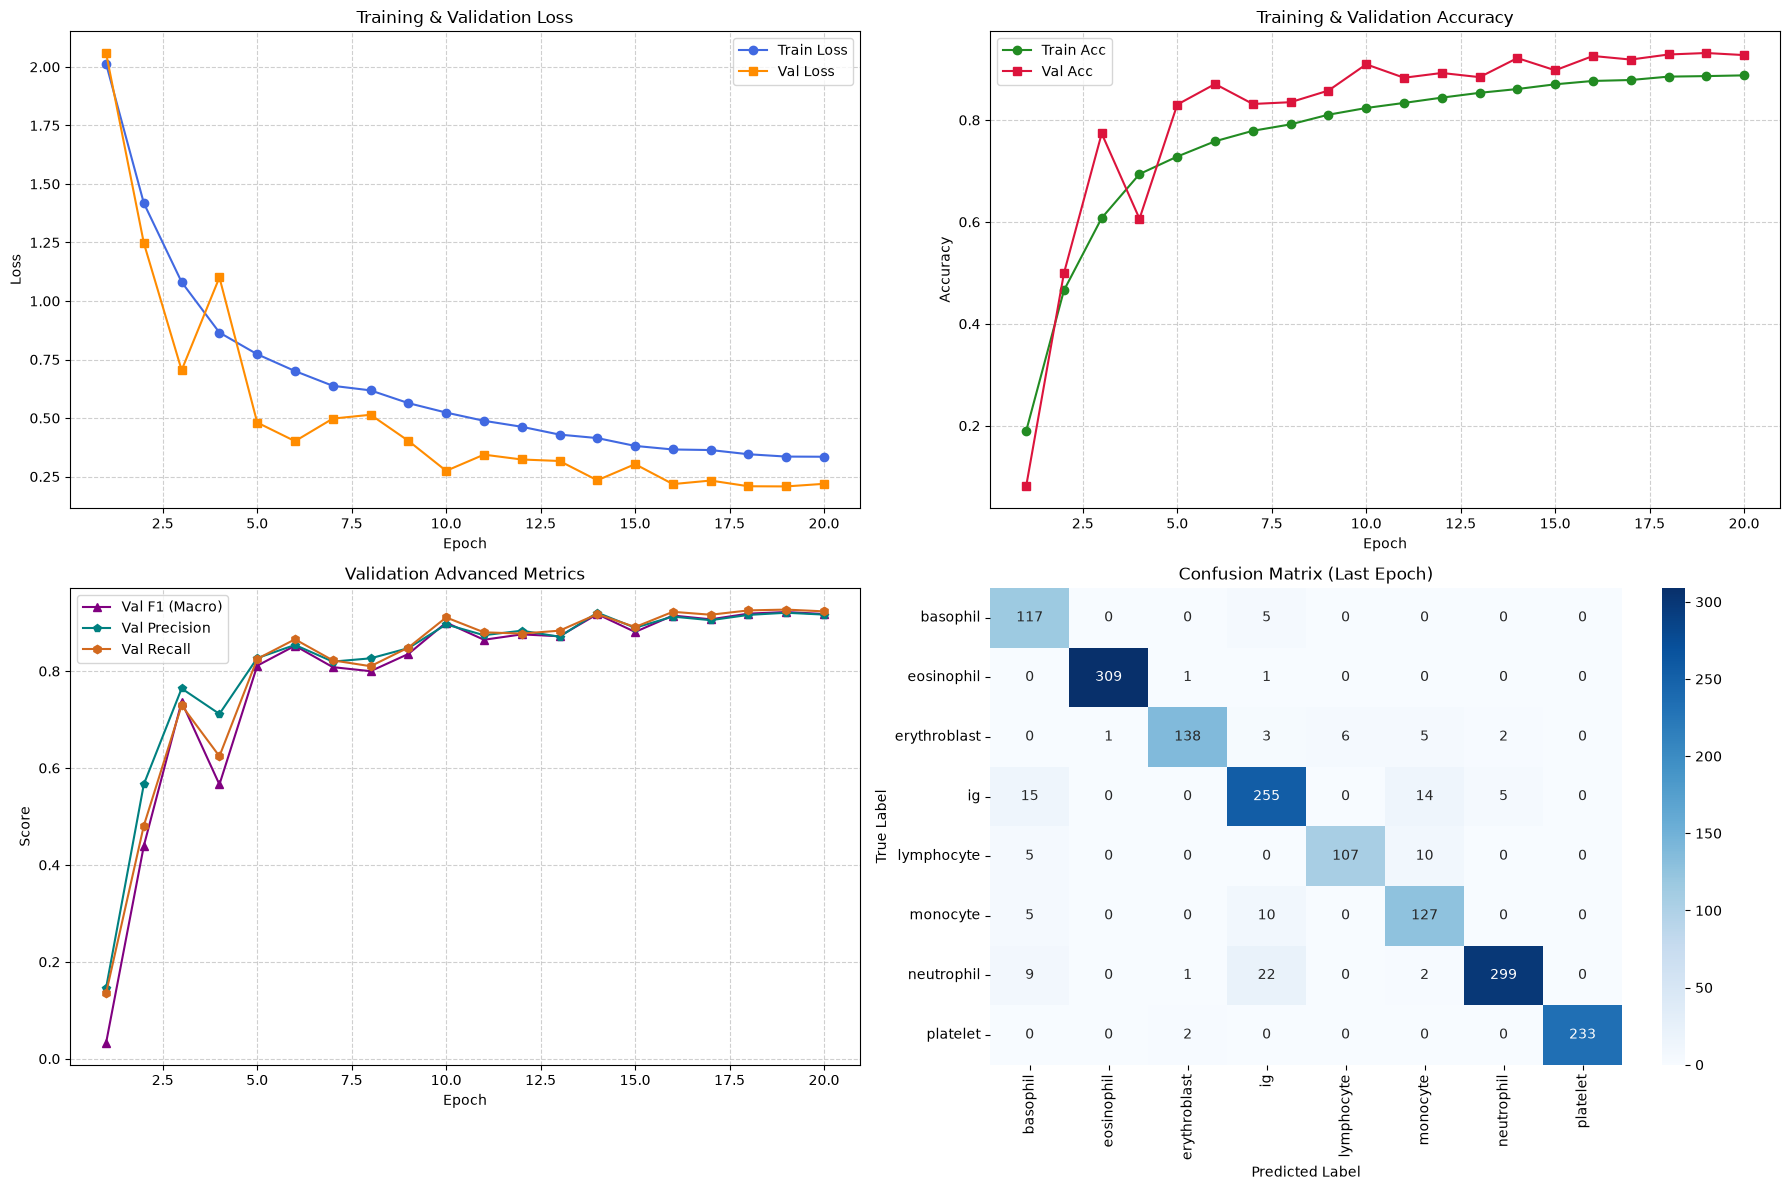

In [23]:
# لیست نام کلاس‌های ۸ تایی خودت را بنویس (ترتیب دقیق رعایت شود)
classes = ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']

plot_advanced_training_history(history, class_names=classes)


In [22]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

output_dir = "training_results"
plots_dir = os.path.join(output_dir, "plots")

os.makedirs(output_dir, exist_ok=True)
os.makedirs(plots_dir, exist_ok=True)


def convert_value(value):
    """Convert tensors and NumPy values to regular Python values."""
    if hasattr(value, "detach"):
        value = value.detach().cpu()

    if hasattr(value, "tolist"):
        value = value.tolist()

    return value


def normalize_metric(values):
    """Convert a metric into a list without modifying the original history."""
    values = convert_value(values)

    if isinstance(values, (list, tuple)):
        return [convert_value(value) for value in values]

    # Preserve scalar metrics as one-element lists.
    return [values]


# Do not modify the original history object.
clean_history = {
    key: normalize_metric(values)
    for key, values in history.items()
    if key != "epoch"
}

# Print lengths to expose incomplete or duplicated metric logging.
print("Recorded metric lengths:")
for key, values in clean_history.items():
    print(f"  {key}: {len(values)}")

max_length = max(len(values) for values in clean_history.values())

# pd.Series pads shorter columns with NaN.
history_df = pd.DataFrame({
    key: pd.Series(values)
    for key, values in clean_history.items()
})

# Generate a fresh, correctly sized epoch column.
history_df.insert(0, "epoch", range(1, max_length + 1))

csv_path = os.path.join(output_dir, "training_history.csv")
json_path = os.path.join(output_dir, "training_history.json")
excel_path = os.path.join(output_dir, "training_history.xlsx")

history_df.to_csv(csv_path, index=False)

# JSON uses null instead of non-standard NaN.
json_records = history_df.replace({np.nan: None}).to_dict(orient="records")
with open(json_path, "w", encoding="utf-8") as file:
    json.dump(json_records, file, indent=4, ensure_ascii=False)

try:
    history_df.to_excel(excel_path, index=False)
    print(f"Excel saved: {excel_path}")
except ImportError:
    print("Excel was not saved because openpyxl is not installed.")
    print("Install it with: pip install openpyxl")

print(f"CSV saved:   {csv_path}")
print(f"JSON saved:  {json_path}")

display(history_df)


Recorded metric lengths:
  train_loss: 20
  train_acc: 20
  val_loss: 20
  val_acc: 20
  val_precision: 20
  val_recall: 20
  val_f1: 20
  train_batch_loss: 34200
  train_batch_acc: 34200
  val_batch_loss: 4280
  val_batch_acc: 4280
  lr: 20
  best_val_loss: 20
  last_val_preds: 1709
  last_val_targets: 1709
Excel was not saved because openpyxl is not installed.
Install it with: pip install openpyxl
CSV saved:   training_results\training_history.csv
JSON saved:  training_results\training_history.json


,epoch,train_loss,train_acc,val_loss,val_acc,val_precision,val_recall,val_f1,train_batch_loss,train_batch_acc,val_batch_loss,val_batch_acc,lr,best_val_loss,last_val_preds,last_val_targets
0,1,2.013664,0.189205,2.059248,0.080749,0.145862,0.135081,0.032454,2.072377,0.250,1.988362,0.000,0.001000,2.059248,7.0,7.0
1,2,1.417693,0.465516,1.247151,0.499122,0.566594,0.481285,0.439542,2.247882,0.000,1.891172,0.250,0.000994,1.247151,7.0,7.0
2,3,1.080753,0.607694,0.704377,0.773552,0.764162,0.729231,0.736468,2.153115,0.000,2.180451,0.250,0.000976,0.704377,1.0,1.0
3,4,0.865101,0.693922,1.100813,0.606202,0.711587,0.624296,0.565975,2.285064,0.375,1.605827,0.000,0.000946,0.704377,6.0,6.0
4,5,0.772546,0.728297,0.480749,0.830310,0.826790,0.825299,0.811112,2.178581,0.250,1.624884,0.125,0.000905,0.480749,7.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34195,34196,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.228181,0.875,NaN,NaN,NaN,NaN,NaN,NaN
34196,34197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.043329,1.000,NaN,NaN,NaN,NaN,NaN,NaN
34197,34198,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.029573,1.000,NaN,NaN,NaN,NaN,NaN,NaN
34198,34199,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.160919,1.000,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
def save_metrics_plot(
    dataframe,
    metric_columns,
    labels,
    title,
    ylabel,
    filename
):
    plt.figure(figsize=(9, 6))
    plotted_anything = False

    for column, label in zip(metric_columns, labels):
        if column not in dataframe.columns:
            print(f"Metric not found, skipped: {column}")
            continue

        valid_rows = dataframe[["epoch", column]].dropna()

        if valid_rows.empty:
            print(f"Metric has no values, skipped: {column}")
            continue

        plt.plot(
            valid_rows["epoch"],
            valid_rows[column],
            marker="o",
            markersize=4,
            linewidth=2,
            label=label
        )
        plotted_anything = True

    if not plotted_anything:
        plt.close()
        print(f"Plot not created: {filename}")
        return

    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    save_path = os.path.join(plots_dir, filename)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Plot saved: {save_path}")


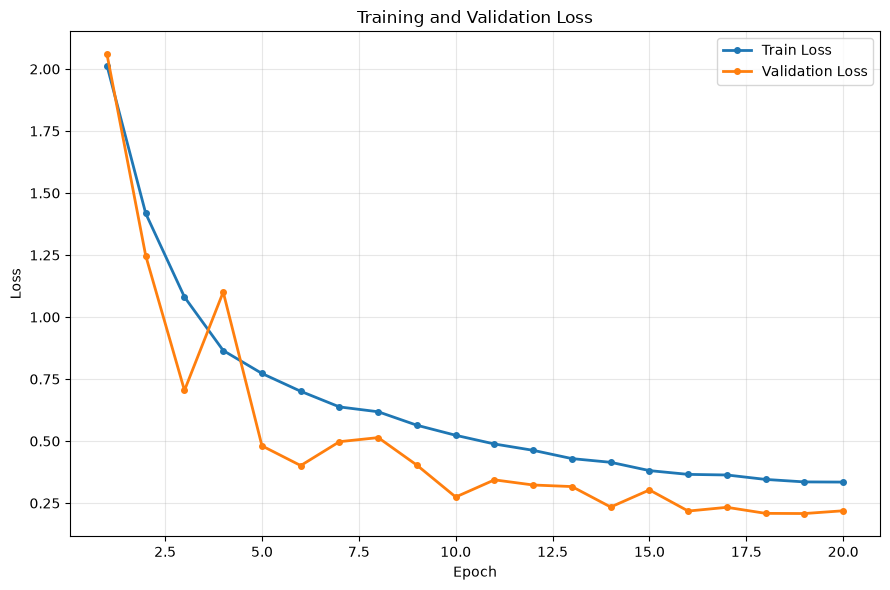

Plot saved: training_results\plots\loss_curve.png


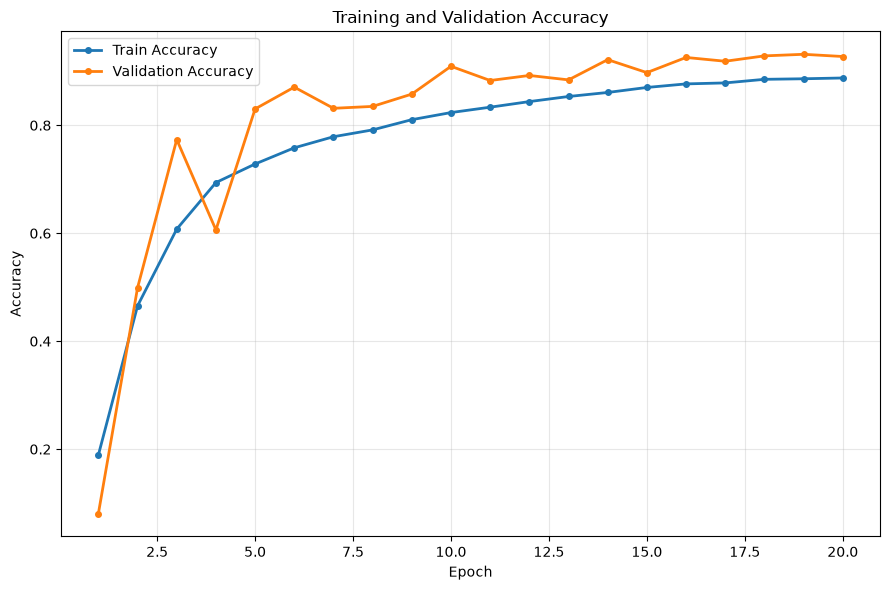

Plot saved: training_results\plots\accuracy_curve.png
Metric not found, skipped: precision
Metric not found, skipped: recall
Metric not found, skipped: f1
Plot not created: validation_metrics.png


In [25]:
save_metrics_plot(
    history_df,
    metric_columns=["train_loss", "val_loss"],
    labels=["Train Loss", "Validation Loss"],
    title="Training and Validation Loss",
    ylabel="Loss",
    filename="loss_curve.png"
)

save_metrics_plot(
    history_df,
    metric_columns=["train_acc", "val_acc"],
    labels=["Train Accuracy", "Validation Accuracy"],
    title="Training and Validation Accuracy",
    ylabel="Accuracy",
    filename="accuracy_curve.png"
)

save_metrics_plot(
    history_df,
    metric_columns=["precision", "recall", "f1"],
    labels=["Precision", "Recall", "F1-score"],
    title="Validation Metrics",
    ylabel="Score",
    filename="validation_metrics.png"
)
